# JOJA — Analyse exploratoire des données

**Équipe :** Samyra Mangan Mben · Tiavina Ranarivelo · Jules Lejeune

## Contexte et objectif

Nous disposons des données d'un site de livraison de courses (jeu de données
Instacart, anonymisé) : **~3,4 millions de commandes** passées par **~206 000
clients**, chaque client ayant entre 4 et 100 commandes. Les produits sont
regroupés en **rayons** (*aisles*), eux-mêmes regroupés en **départements**.

Objectif : explorer ces données pour en tirer des **insights actionnables** —
des constats chiffrés qui débouchent sur une décision concrète que l'enseigne
peut prendre pour améliorer son activité.

## Les données — 5 fichiers

| Fichier | Une ligne = | Colonnes clés |
|---|---|---|
| `orders` | une commande | `order_id`, `user_id`, `order_number` (rang de la commande du client), `order_dow` (jour, 0 = dimanche), `order_hour_of_day` (heure), `days_since_prior_order` |
| `order_products` | un produit dans une commande | `order_id`, `product_id`, `add_to_cart_order` (position dans le panier), `reordered` (1 = déjà commandé avant) |
| `products` | un produit | `product_id`, `product_name`, `aisle_id`, `department_id` |
| `aisles` | un rayon | `aisle_id`, `aisle` |
| `departments` | un département | `department_id`, `department` |

### Modèle relationnel (schéma en étoile)

```
order_products ──(order_id)──▶ orders ──(user_id)──▶ clients
      │
      └──(product_id)──▶ products ──(aisle_id)──────▶ aisles
                                 └─(department_id)──▶ departments
```

Les fichiers se relient par leurs colonnes `_id`. La table centrale est
`order_products` : c'est le grain le plus fin (un article acheté).


## Méthodologie

Nous suivons une démarche d'analyse exploratoire (*EDA*) en cinq étapes :

1. **Chargement et typage** — lire les fichiers, choisir des types adaptés au volume.
2. **Contrôle qualité** — dimensions, valeurs manquantes, valeurs aberrantes.
3. **Préparation** — recoller les tables de référence (produits → rayons → départements).
4. **Analyse question par question** — pour chaque question : problème → mesure → **un** graphique adapté → observation → piste d'action.
5. **Synthèse** — regrouper les observations en recommandations.

## Outils et justification des choix

| Paquet | Rôle | Pourquoi ce choix |
|---|---|---|
| **pandas** | manipulation de données tabulaires | standard de fait en Python ; structure `DataFrame` expressive ; gère nos volumes (32 M lignes) en mémoire vive |
| **numpy** | calcul numérique vectorisé | socle de pandas ; opérations sur des tableaux entiers sans boucle Python (rapide) |
| **matplotlib** | graphiques | bibliothèque de référence, contrôle fin de chaque élément du graphique (axes, titres, légendes) |
| **seaborn** | graphiques statistiques | surcouche de matplotlib : agrège et met en forme en une ligne (barres avec intervalles, heatmaps) ; introduite à partir des questions qui en ont besoin |

**Fonctionnement en bref.** pandas charge chaque fichier dans un `DataFrame`
(un tableau indexé) et exécute les opérations d'agrégation en s'appuyant sur les
tableaux numpy sous-jacents. matplotlib construit les figures comme un empilement
d'objets (`Figure` → `Axes` → tracés) que l'on paramètre explicitement ; seaborn
appelle matplotlib en dessous.

## Règle sur les visualisations

Nous n'utilisons pas le même graphique pour des besoins différents :

| Besoin | Graphique retenu |
|---|---|
| **distribution** (répartition d'une variable) | histogramme, boîte à moustaches |
| **comparaison** (classer des catégories) | diagramme en barres |
| **proportion** (part d'un tout) | barres empilées à 100 % |
| **relation** (lien entre deux variables) | nuage de points, carte de chaleur |


---
# 1. Préparation des données

## 1.1 Chargement et typage


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.2f}".format)  # nombres lisibles (pas de notation 1e+06)

In [2]:
orders      = pd.read_csv("datasets/orders.csv")
products    = pd.read_csv("datasets/products.csv")
aisles      = pd.read_csv("datasets/aisles.csv")
departments = pd.read_csv("datasets/departments.csv")

# order_products : 32 M lignes. On impose des types compacts pour diviser
# l'empreinte mémoire par ~3 (int8/int16/int32 au lieu de l'int64 par défaut).
types_op = {"order_id": "int32", "product_id": "int32",
            "add_to_cart_order": "int16", "reordered": "int8"}
order_products = pd.read_csv("datasets/order_products.csv", dtype=types_op)

for nom, df in [("orders", orders), ("order_products", order_products),
                ("products", products), ("aisles", aisles), ("departments", departments)]:
    print(f"{nom:<15} {df.shape[0]:>10,} lignes  {df.shape[1]} colonnes")

orders           3,421,083 lignes  7 colonnes
order_products  32,434,489 lignes  4 colonnes
products            49,688 lignes  4 colonnes
aisles                 134 lignes  2 colonnes
departments             21 lignes  2 colonnes


**Justification du typage.** Une colonne comme `reordered` ne contient que 0
ou 1 : un `int8` (1 octet) suffit là où pandas prendrait un `int64` (8 octets).
Sur 32 millions de lignes, l'écart se compte en centaines de mégaoctets. Les
`id` tiennent tous dans un `int32` (valeur max ~3,4 M).


## 1.2 Tables de référence : produits enrichis

`products` ne contient que les identifiants de rayon et de département. Nous
rapprochons (`merge`) les libellés pour disposer d'une table produit lisible,
réutilisée dans toutes les analyses.


In [3]:
produits = (
    products
    .merge(aisles, on="aisle_id")            # ajoute la colonne 'aisle'
    .merge(departments, on="department_id")  # ajoute la colonne 'department'
)
produits = produits[["product_id", "product_name", "aisle", "department"]]
produits.head()

,product_id,product_name,aisle,department
0,1,Chocolate Sandwich Cookies,cookies cakes,snacks
1,2,All-Seasons Salt,spices seasonings,pantry
2,3,Robust Golden Unsweetened Oolong Tea,tea,beverages
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,frozen meals,frozen
4,5,Green Chile Anytime Sauce,marinades meat preparation,pantry


## 1.3 Contrôle qualité

Recherche des valeurs manquantes sur la table `orders`.


In [4]:
orders.isna().sum()

order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64

Seule `days_since_prior_order` présente des valeurs manquantes. Vérifions
sur quelles lignes.


In [5]:
orders.loc[orders["days_since_prior_order"].isna(), "order_number"].value_counts()

order_number
1    206209
Name: count, dtype: int64

**Interprétation.** Les valeurs manquantes tombent **toutes** sur
`order_number == 1` : la première commande d'un client n'a pas de commande
antérieure, donc pas de délai. Il s'agit d'une absence légitime, non d'une
donnée corrompue.

**Décision.** Nous conservons ces `NaN` tels quels : les remplacer par 0
fausserait le calcul du délai moyen entre commandes. pandas les exclut
automatiquement des agrégations (`mean`, `median`).

Par ailleurs `describe()` (ci-dessous) montre que `days_since_prior_order` est
plafonnée à 30 : toute valeur « 30 jours ou plus » est codée 30.


In [6]:
orders.describe()

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
count,3421083.00,3421083.00,3421083.00,3421083.00,3421083.00,3214874.00
mean,1710542.00,102978.21,17.15,2.78,13.45,11.11
std,987581.74,59533.72,17.73,2.05,4.23,9.21
min,1.00,1.00,1.00,0.00,0.00,0.00
25%,855271.50,51394.00,5.00,1.00,10.00,4.00
50%,1710542.00,102689.00,11.00,3.00,13.00,7.00
75%,2565812.50,154385.00,23.00,5.00,16.00,15.00
max,3421083.00,206209.00,100.00,6.00,23.00,30.00


---
# 2. Analyses exploratoires

## Q1 — Combien d'articles les clients commandent-ils par commande ?

**Problème.** Connaître la taille typique d'un panier, et repérer les commandes
atypiques (très petites ou très grandes).

**Mesure.** Nombre de lignes de `order_products` par `order_id`
(`groupby` + `size`).

**Graphique.** C'est une **distribution** → histogramme.


In [7]:
articles_par_commande = order_products.groupby("order_id").size()
articles_par_commande.describe()

count   3214874.00
mean         10.09
std           7.53
min           1.00
25%           5.00
50%           8.00
75%          14.00
max         145.00
dtype: float64

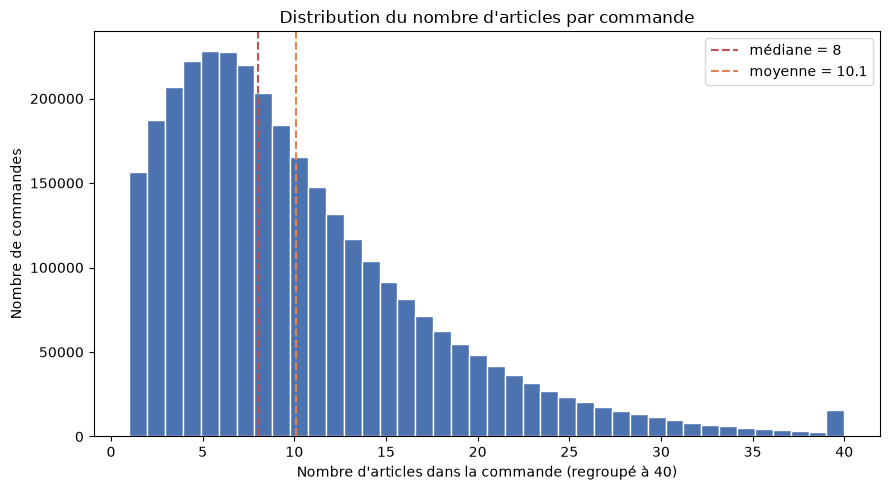

In [8]:
seuil = 40  # au-delà : moins de 1 % des commandes ; on les regroupe pour garder un graphe lisible

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(articles_par_commande.clip(upper=seuil), bins=seuil, color="#4C72B0", edgecolor="white")
ax.axvline(articles_par_commande.median(), color="#C44E52", linestyle="--",
           label=f"médiane = {articles_par_commande.median():.0f}")
ax.axvline(articles_par_commande.mean(), color="#DD8452", linestyle="--",
           label=f"moyenne = {articles_par_commande.mean():.1f}")
ax.set_xlabel("Nombre d'articles dans la commande (regroupé à 40)")
ax.set_ylabel("Nombre de commandes")
ax.set_title("Distribution du nombre d'articles par commande")
ax.legend()
fig.tight_layout()
plt.show()

In [9]:
part_1 = (articles_par_commande == 1).mean()
print(f"Commandes à 1 seul article : {part_1:.1%}")

Commandes à 1 seul article : 4.9%


**Observations.**

- Panier **médian : 8 articles** ; moyenne **10,1**. La moyenne est supérieure à
  la médiane : la distribution est **étirée vers la droite** (quelques très
  grosses commandes, jusqu'à 145 articles).
- Le mode se situe autour de **5-6 articles**.
- Environ **5 %** des commandes ne contiennent qu'**un seul article**.

**Insight actionnable.** Les commandes de 1 à 3 articles représentent un volume
non négligeable et un panier très faible. Proposer sur ces commandes des
suggestions « souvent achetés ensemble » (cross-sell) est une piste directe
d'augmentation du panier moyen — à préciser avec une analyse de co-occurrence
de produits (question ultérieure).
